# Phase 5 — Machine Learning for Operational Intelligence

## Objective

Use road-network, traffic, weather and operational data to improve
travel-time prediction and logistics decisions.

## Planned Work

- Extract road-network features using OSMnx and OpenStreetMap.
- Analyse road connectivity, classifications and junction density.
- Investigate and integrate traffic and weather data where available.
- Build a dataset for travel-time prediction.
- Train and evaluate baseline Machine Learning models.
- Integrate improved travel-time estimates into the existing
  Phase 4 optimization engine.

## Dependencies

- Phase 2: Geospatial data and network distances.
- Phase 3: Baseline dispatch logic.
- Phase 4: Route optimization and estimated travel times.

## Data Requirements

- Existing delivery and rider data.
- OpenStreetMap road-network data.
- Travel-time estimates from Phase 4.
- Traffic and weather data, where available.
- Actual journey observations for real-world model validation.

In [2]:
# Placeholder - Phase 5 is not yet implemented
print("Phase 5: Travel Time Prediction - IMPLEMENTATION")

Phase 5: Travel Time Prediction - IMPLEMENTATION


In [3]:
# PHASE 5: INSPECT SCENARIO ASSUMPTIONS

import pandas as pd
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "raw" / "scenario.csv").exists()
)

scenario = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "scenario.csv"
)

print("SCENARIO DATA")
print("=" * 50)
print("Shape:", scenario.shape)
print("Columns:", list(scenario.columns))

display(scenario)

print("\nDELIVERY SERVICE-TIME SUMMARY")
print("=" * 50)

deliveries = pd.read_csv(
    PROJECT_ROOT / "data" / "raw" / "deliveries.csv"
)

print(deliveries["service_time_min"].describe())

SCENARIO DATA
Shape: (1, 9)
Columns: ['scenario_id', 'city', 'country', 'registered_riders', 'planned_deliveries', 'vehicle_type', 'depot_count', 'scenario_type', 'random_seed']


,scenario_id,city,country,registered_riders,planned_deliveries,vehicle_type,depot_count,scenario_type,random_seed
0,LAGOS_V1_DAY001,Lagos,Nigeria,6,60,motorcycle,1,synthetic,42



DELIVERY SERVICE-TIME SUMMARY
count    60.000000
mean      9.133333
std       3.321561
min       5.000000
25%       7.000000
50%       7.000000
75%      12.000000
max      15.000000
Name: service_time_min, dtype: float64


In [4]:
# PHASE 5.1: EXISTING DATA AUDIT

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"


DATA_RAW = Path(DATA_RAW)
DATA_PROCESSED = Path(DATA_PROCESSED)

files_to_check = {
    "Deliveries": DATA_RAW / "deliveries.csv",
    "Depot": DATA_RAW / "depot.csv",
    "Riders": DATA_RAW / "riders.csv",
    "Scenario": DATA_RAW / "scenario.csv",
    "Distance matrix": (
        DATA_PROCESSED / "network_distance_matrix.csv"
    ),
    "Travel-time observations": (
        DATA_RAW / "travel_time_observations.csv"
    ),
}

print("=" * 70)
print("PHASE 5.1: CURRENT DATA INVENTORY")
print("=" * 70)

for name, path in files_to_check.items():
    print(f"\n{name}: {path}")

    if not path.exists():
        print("STATUS: NOT FOUND")
        continue

    print("STATUS: FOUND")

    if path.suffix.lower() != ".csv":
        continue

    df = pd.read_csv(path)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    if name == "Distance matrix":
        matrix = pd.read_csv(path, index_col=0)

        values = matrix.to_numpy(dtype=float)

        print("Shape:", matrix.shape)
        print("Row IDs unique:", matrix.index.is_unique)
        print("Column IDs unique:", matrix.columns.is_unique)
        print("All values finite:", np.isfinite(values).all())
        print("Minimum value:", np.nanmin(values))
        print("Maximum value:", np.nanmax(values))
        print(
            "Diagonal is zero:",
            np.allclose(np.diag(values), 0)
        )

    elif name in ("Deliveries", "Depot"):
        display(df.head())

PHASE 5.1: CURRENT DATA INVENTORY

Deliveries: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\raw\deliveries.csv
STATUS: FOUND
Rows: 60
Columns: ['delivery_id', 'customer_id', 'area', 'latitude', 'longitude', 'weight_kg', 'package_size', 'priority', 'window_start', 'window_end', 'service_time_min']


,delivery_id,customer_id,area,latitude,longitude,weight_kg,package_size,priority,window_start,window_end,service_time_min
0,D001,C001,Maryland,6.575974,3.365894,2.1,SMALL,NORMAL,14:00,18:00,15
1,D002,C002,Surulere,6.502082,3.365384,5.2,MEDIUM,NORMAL,12:00,16:00,5
2,D003,C003,Maryland,6.570127,3.365127,9.9,MEDIUM,NORMAL,12:00,16:00,10
3,D004,C004,Victoria Island,6.440734,3.428039,4.2,SMALL,HIGH,10:00,14:00,7
4,D005,C005,Yaba,6.512044,3.375040,5.7,MEDIUM,NORMAL,10:00,14:00,10



Depot: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\raw\depot.csv
STATUS: FOUND
Rows: 1
Columns: ['depot_id', 'depot_name', 'area', 'latitude', 'longitude', 'opening_time', 'closing_time']


,depot_id,depot_name,area,latitude,longitude,opening_time,closing_time
0,DEP001,Apapa Central Depot,Apapa,6.4483,3.359,07:00,20:00



Riders: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\raw\riders.csv
STATUS: FOUND
Rows: 6
Columns: ['rider_id', 'vehicle_type', 'available', 'shift_start', 'shift_end', 'break_start', 'break_end', 'capacity_kg', 'max_packages']

Scenario: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\raw\scenario.csv
STATUS: FOUND
Rows: 1
Columns: ['scenario_id', 'city', 'country', 'registered_riders', 'planned_deliveries', 'vehicle_type', 'depot_count', 'scenario_type', 'random_seed']

Distance matrix: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\processed\network_distance_matrix.csv
STATUS: FOUND
Rows: 61
Columns: ['Unnamed: 0', 'DEP001', 'D001', 'D002', 'D003', 'D004', 'D005', 'D006', 'D007', 'D008', 'D009', 'D010', 'D011', 'D012', 'D013

In [5]:
# PHASE 5.3: OSM ROAD-NETWORK EXTRACTION

import osmnx as ox
import pandas as pd
import numpy as np
import geopandas as gpd
import networkx as nx

from pathlib import Path

In [6]:
# PROJECT PATHS

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "raw" / "deliveries.csv").exists()
)

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

NETWORK_DIR = DATA_PROCESSED / "phase5_network"

NETWORK_DIR.mkdir(parents=True, exist_ok=True)

# LOAD DELIVERIES

deliveries = pd.read_csv(
    DATA_RAW / "deliveries.csv"
)

print("DELIVERY DATA")
print("=" * 60)

print("Shape:", deliveries.shape)
print("Columns:", deliveries.columns.tolist())

display(deliveries.head())

DELIVERY DATA
Shape: (60, 11)
Columns: ['delivery_id', 'customer_id', 'area', 'latitude', 'longitude', 'weight_kg', 'package_size', 'priority', 'window_start', 'window_end', 'service_time_min']


,delivery_id,customer_id,area,latitude,longitude,weight_kg,package_size,priority,window_start,window_end,service_time_min
0,D001,C001,Maryland,6.575974,3.365894,2.1,SMALL,NORMAL,14:00,18:00,15
1,D002,C002,Surulere,6.502082,3.365384,5.2,MEDIUM,NORMAL,12:00,16:00,5
2,D003,C003,Maryland,6.570127,3.365127,9.9,MEDIUM,NORMAL,12:00,16:00,10
3,D004,C004,Victoria Island,6.440734,3.428039,4.2,SMALL,HIGH,10:00,14:00,7
4,D005,C005,Yaba,6.512044,3.375040,5.7,MEDIUM,NORMAL,10:00,14:00,10


In [7]:
# IDENTIFY COORDINATE COLUMNS

latitude_candidates = [
    "latitude",
    "lat",
    "delivery_lat",
    "destination_lat",
    "dropoff_lat"
]

longitude_candidates = [
    "longitude",
    "lon",
    "lng",
    "delivery_lon",
    "delivery_lng",
    "destination_lon",
    "dropoff_lon"
]

lat_col = next(
    (col for col in latitude_candidates if col in deliveries.columns),
    None
)

lon_col = next(
    (col for col in longitude_candidates if col in deliveries.columns),
    None
)

if lat_col is None or lon_col is None:
    raise ValueError(
        "Could not identify latitude and longitude columns. "
        "Check the delivery CSV column names and set lat_col/lon_col manually."
    )

print("Latitude column:", lat_col)
print("Longitude column:", lon_col)

# CLEAN COORDINATES

delivery_locations = deliveries.copy()

delivery_locations[lat_col] = pd.to_numeric(
    delivery_locations[lat_col],
    errors="coerce"
)

delivery_locations[lon_col] = pd.to_numeric(
    delivery_locations[lon_col],
    errors="coerce"
)

delivery_locations = delivery_locations.dropna(
    subset=[lat_col, lon_col]
)

# Basic coordinate validation

valid_coordinates = (
    delivery_locations[lat_col].between(-90, 90)
    & delivery_locations[lon_col].between(-180, 180)
)

delivery_locations = delivery_locations.loc[
    valid_coordinates
].copy()

if delivery_locations.empty:
    raise ValueError("No valid delivery coordinates found.")

print("\nValid delivery locations:", len(delivery_locations))

print(
    delivery_locations[[lat_col, lon_col]].describe()
)

Latitude column: latitude
Longitude column: longitude

Valid delivery locations: 60
        latitude  longitude
count  60.000000  60.000000
mean    6.501810   3.393730
std     0.052740   0.070569
min     6.423295   3.333730
25%     6.454906   3.352750
50%     6.495559   3.365255
75%     6.525332   3.410877
max     6.613525   3.597717


In [8]:
# CREATE BOUNDING BOX

BUFFER_METERS = 2000

mean_latitude = delivery_locations[lat_col].mean()

latitude_buffer = BUFFER_METERS / 111_320

longitude_buffer = (
    BUFFER_METERS
    / (111_320 * np.cos(np.radians(mean_latitude)))
)

north = delivery_locations[lat_col].max() + latitude_buffer
south = delivery_locations[lat_col].min() - latitude_buffer

east = delivery_locations[lon_col].max() + longitude_buffer
west = delivery_locations[lon_col].min() - longitude_buffer

print("NETWORK BOUNDING BOX")
print("=" * 60)

print("North:", north)
print("South:", south)
print("East:", east)
print("West:", west)
print("Buffer:", BUFFER_METERS, "metres")

NETWORK BOUNDING BOX
North: 6.63149122349982
South: 6.4053287765001805
East: 3.6157995252469437
West: 3.315647474753056
Buffer: 2000 metres


In [9]:
# PHASE 5.3.3: DEFINE LAGOS STUDY AREA

import osmnx as ox
import geopandas as gpd
import pandas as pd
from pathlib import Path
import time

# Retrieve Lagos State boundary
lagos = ox.geocode_to_gdf(
    "Lagos State, Nigeria"
)

print("LAGOS STUDY AREA")
print("=" * 60)
print("CRS:", lagos.crs)
print("Area:", lagos.to_crs("EPSG:32631").area.sum() / 1_000_000, "km²")

# Save boundary for reuse
lagos.to_file(
    NETWORK_DIR / "lagos_boundary.geojson",
    driver="GeoJSON"
)

display(lagos)

LAGOS STUDY AREA
CRS: epsg:4326
Area: 3704.1479121004545 km²


,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,osm_type,osm_id,lat,lon,class,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((2.70598 6.42129, 2.70636 6.40298, 2....",2.705985,6.366684,4.350906,6.696796,41167547,relation,3718182,6.526903,3.5774,boundary,administrative,8,0.547811,state,Lagos State,"Lagos State, Nigeria"


In [10]:
# PHASE 5.3.4: DOWNLOAD LAGOS ROAD NETWORK

print("Downloading Lagos road network...")

ox.settings.use_cache = True
ox.settings.log_console = True

G = ox.graph_from_polygon(
    lagos.geometry.iloc[0],
    network_type="drive",
    simplify=True,
    retain_all=True,
    truncate_by_edge=True
)

print("\nDOWNLOAD COMPLETE")
print("=" * 60)

print("Nodes:", len(G.nodes))
print("Edges:", len(G.edges))
print("Directed:", G.is_directed())
print("CRS:", G.graph["crs"])


DOWNLOAD COMPLETE
Nodes: 98859
Edges: 241018
Directed: True
CRS: epsg:4326


In [11]:
# CONVERT GRAPH TO GEODATAFRAMES

nodes, edges = ox.graph_to_gdfs(
    G,
    nodes=True,
    edges=True
)

print("NODE DATA")
print("=" * 60)
print("Shape:", nodes.shape)
print("Columns:", nodes.columns.tolist())

print("\nEDGE DATA")
print("=" * 60)
print("Shape:", edges.shape)
print("Columns:", edges.columns.tolist())

display(nodes.head())
display(edges.head())

NODE DATA
Shape: (98859, 6)
Columns: ['y', 'x', 'street_count', 'highway', 'railway', 'geometry']

EDGE DATA
Shape: (241018, 15)
Columns: ['osmid', 'highway', 'oneway', 'reversed', 'length', 'geometry', 'bridge', 'name', 'lanes', 'ref', 'maxspeed', 'junction', 'access', 'tunnel', 'width']


,y,x,street_count,highway,railway,geometry
osmid,,,,,,
3202618256,6.398621,4.266580,3,NaN,NaN,POINT (4.26658 6.39862)
3202618257,6.398458,4.269251,4,NaN,NaN,POINT (4.26925 6.39846)
3202622663,6.415313,4.094761,3,NaN,NaN,POINT (4.09476 6.41531)
3202622665,6.415846,4.093400,3,NaN,NaN,POINT (4.0934 6.41585)
3202622669,6.416214,4.090032,3,NaN,NaN,POINT (4.09003 6.41621)


osmid  \
u          v           key                                         
3202618256 10175580642 0                              1112250923   
           3202618257  0                              1113440116   
           10184357068 0                              1113440116   
3202618257 10175580617 0                              1112250921   
           10184357040 0    [1113158587, 1113158588, 1113158589]   

                                 highway  oneway reversed       length  \
u          v           key                                               
3202618256 10175580642 0     residential   False     True   275.258490   
           3202618257  0    unclassified   False    False   295.898661   
           10184357068 0    unclassified   False     True  1350.114896   
3202618257 10175580617 0     residential   False     True   128.580805   
           10184357040 0    unclassified   False     True  1781.836247   

                                                                     geometry  \
u          v           key                                                      
3202618256 10175580642 0    LINESTRING (4.26658 6.39862, 4.26659 6.39911, ...   
           3202618257  0    LINESTRING (4.26658 6.39862, 4.2669 6.39857, 4...   
           10184357068 0    LINESTRING (4.26658 6.39862, 4.26483 6.39891, ...   
3202618257 10175580617 0    LINESTRING (4.26925 6.39846, 4.26959 6.39953, ...   
           10184357040 0    LINESTRING (4.26925 6.39846, 4.26907 6.39811, ...   

                           bridge name lanes  ref maxspeed junction access  \
u          v           key                                                   
3202618256 10175580642 0      NaN  NaN   NaN  NaN      NaN      NaN    NaN   
           3202618257  0      NaN  NaN   NaN  NaN      NaN      NaN    NaN   
           10184357068 0      NaN  NaN   NaN  NaN      NaN      NaN    NaN   
3202618257 10175580617 0      NaN  NaN   NaN  NaN      NaN      NaN    NaN   
           10184357040 0      yes  NaN   NaN  NaN      NaN      NaN    NaN   

                           tunnel width  
u          v           key               
3202618256 10175580642 0      NaN   NaN  
           3202618257  0      NaN   NaN  
           10184357068 0      NaN   NaN  
3202618257 10175580617 0      NaN   NaN  
           10184357040 0      NaN   NaN

In [12]:
# INSPECT ROAD CLASSIFICATIONS

if "highway" in edges.columns:

    road_classifications = (
        edges["highway"]
        .explode()
        .value_counts(dropna=False)
        .rename_axis("road_class")
        .reset_index(name="segment_count")
    )

    print("ROAD CLASSIFICATION SUMMARY")
    print("=" * 60)

    display(road_classifications)

else:
    print("No highway classification column found.")

ROAD CLASSIFICATION SUMMARY


,road_class,segment_count
0,residential,206525
1,tertiary,11602
2,unclassified,10440
3,secondary,5409
4,primary,3730
5,trunk,1798
6,motorway_link,335
7,trunk_link,310
8,motorway,277
9,primary_link,270


In [13]:
node_connectivity = pd.DataFrame({
    "node_id": nodes.index,
    "connection_count": [
        len(list(G.successors(node))) + len(list(G.predecessors(node)))
        for node in nodes.index
    ],
    "is_junction": [
        (len(list(G.successors(node))) + len(list(G.predecessors(node)))) > 2
        for node in nodes.index
    ]
})

In [14]:
# MERGE CONNECTIVITY WITH NODE DATA

nodes = nodes.join(
    node_connectivity.set_index("node_id"),
    how="left"
)

nodes["connection_count"] = (
    nodes["connection_count"].fillna(0).astype(int)
)

nodes["is_junction"] = (
    nodes["is_junction"].fillna(False).astype(bool)
)

print("UPDATED NODE DATA")
print("=" * 60)

display(
    nodes[
        [
            "connection_count",
            "is_junction",
            "geometry"
        ]
    ].head()
)

UPDATED NODE DATA


,connection_count,is_junction,geometry
osmid,,,
3202618256,6,True,POINT (4.26658 6.39862)
3202618257,8,True,POINT (4.26925 6.39846)
3202622663,6,True,POINT (4.09476 6.41531)
3202622665,6,True,POINT (4.0934 6.41585)
3202622669,6,True,POINT (4.09003 6.41621)


In [15]:
# only do this once
nodes = nodes.drop(columns=["connection_count", "is_junction"], errors="ignore")

nodes = nodes.join(
    node_connectivity.set_index("node_id"),
    how="left"
)

nodes["connection_count"] = (
    nodes["connection_count"].fillna(0).astype(int)
)

nodes["is_junction"] = (
    nodes["is_junction"].fillna(False).astype(bool)
)

print("UPDATED NODE DATA")
print("=" * 60)

display(
    nodes[
        [
            "connection_count",
            "is_junction",
            "geometry"
        ]
    ].head()
)

UPDATED NODE DATA


,connection_count,is_junction,geometry
osmid,,,
3202618256,6,True,POINT (4.26658 6.39862)
3202618257,8,True,POINT (4.26925 6.39846)
3202622663,6,True,POINT (4.09476 6.41531)
3202622665,6,True,POINT (4.0934 6.41585)
3202622669,6,True,POINT (4.09003 6.41621)


In [16]:
# PREPARE EDGE FEATURES

edges = edges.copy()

def get_primary_value(value):
    if isinstance(value, list):
        return value[0] if value else np.nan

    return value

# Extract commonly useful road attributes

for column in [
    "highway",
    "name",
    "maxspeed",
    "lanes",
    "surface",
    "oneway",
    "bridge",
    "tunnel",
    "access"
]:
    if column in edges.columns:
        edges[f"{column}_value"] = edges[column].apply(
            get_primary_value
        )

# Road length is normally provided by OSMnx in metres

if "length" in edges.columns:
    edges["length_km"] = edges["length"] / 1000

print("EDGE FEATURES")
print("=" * 60)

display(edges.head())

EDGE FEATURES


osmid  \
u          v           key                                         
3202618256 10175580642 0                              1112250923   
           3202618257  0                              1113440116   
           10184357068 0                              1113440116   
3202618257 10175580617 0                              1112250921   
           10184357040 0    [1113158587, 1113158588, 1113158589]   

                                 highway  oneway reversed       length  \
u          v           key                                               
3202618256 10175580642 0     residential   False     True   275.258490   
           3202618257  0    unclassified   False    False   295.898661   
           10184357068 0    unclassified   False     True  1350.114896   
3202618257 10175580617 0     residential   False     True   128.580805   
           10184357040 0    unclassified   False     True  1781.836247   

                                                                     geometry  \
u          v           key                                                      
3202618256 10175580642 0    LINESTRING (4.26658 6.39862, 4.26659 6.39911, ...   
           3202618257  0    LINESTRING (4.26658 6.39862, 4.2669 6.39857, 4...   
           10184357068 0    LINESTRING (4.26658 6.39862, 4.26483 6.39891, ...   
3202618257 10175580617 0    LINESTRING (4.26925 6.39846, 4.26959 6.39953, ...   
           10184357040 0    LINESTRING (4.26925 6.39846, 4.26907 6.39811, ...   

                           bridge name lanes  ref  ... width highway_value  \
u          v           key                         ...                       
3202618256 10175580642 0      NaN  NaN   NaN  NaN  ...   NaN   residential   
           3202618257  0      NaN  NaN   NaN  NaN  ...   NaN  unclassified   
           10184357068 0      NaN  NaN   NaN  NaN  ...   NaN  unclassified   
3202618257 10175580617 0      NaN  NaN   NaN  NaN  ...   NaN   residential   
           10184357040 0      yes  NaN   NaN  NaN  ...   NaN  unclassified   

                           name_value maxspeed_value lanes_value oneway_value  \
u          v           key                                                      
3202618256 10175580642 0          NaN            NaN         NaN        False   
           3202618257  0          NaN            NaN         NaN        False   
           10184357068 0          NaN            NaN         NaN        False   
3202618257 10175580617 0          NaN            NaN         NaN        False   
           10184357040 0          NaN            NaN         NaN        False   

                           bridge_value tunnel_value access_value  length_km  
u          v           key                                                    
3202618256 10175580642 0            NaN          NaN          NaN   0.275258  
           3202618257  0            NaN          NaN          NaN   0.295899  
           10184357068 0            NaN          NaN          NaN   1.350115  
3202618257 10175580617 0            NaN          NaN          NaN   0.128581  
           10184357040 0            yes          NaN          NaN   1.781836  

[5 rows x 24 columns]

In [17]:
# SAVE NETWORK DATASETS

# Geographic files
nodes.to_file(
    NETWORK_DIR / "osm_nodes.geojson",
    driver="GeoJSON"
)

edges.to_file(
    NETWORK_DIR / "osm_edges.geojson",
    driver="GeoJSON"
)

# Tabular files
nodes_table = nodes.copy()
edges_table = edges.copy()

nodes_table["geometry"] = nodes_table.geometry.to_wkt()
edges_table["geometry"] = edges_table.geometry.to_wkt()

nodes_table.to_csv(
    NETWORK_DIR / "osm_nodes.csv",
    index=True
)

edges_table.to_csv(
    NETWORK_DIR / "osm_edges.csv",
    index=True
)

node_connectivity.to_csv(
    NETWORK_DIR / "osm_node_connectivity.csv",
    index=False
)

road_classifications.to_csv(
    NETWORK_DIR / "osm_road_classifications.csv",
    index=False
)

# Save the graph itself for later reuse
ox.save_graphml(
    G,
    filepath=NETWORK_DIR / "osm_road_network.graphml"
)

print("NETWORK DATASETS SAVED")
print("=" * 60)

for path in NETWORK_DIR.iterdir():
    print(path.name)

C:\Users\ginik\AppData\Local\Temp\ipykernel_5264\2614631977.py:18: UserWarning: Geometry column does not contain geometry.
  nodes_table["geometry"] = nodes_table.geometry.to_wkt()
C:\Users\ginik\AppData\Local\Temp\ipykernel_5264\2614631977.py:19: UserWarning: Geometry column does not contain geometry.
  edges_table["geometry"] = edges_table.geometry.to_wkt()


NETWORK DATASETS SAVED
lagos_boundary.geojson
osm_edges.csv
osm_edges.geojson
osm_nodes.csv
osm_nodes.geojson
osm_node_connectivity.csv
osm_road_classifications.csv
osm_road_network.graphml


In [18]:
# PHASE 5.3: EXTRACTION SUMMARY

print("=" * 70)
print("PHASE 5.3: OSM ROAD-NETWORK EXTRACTION REPORT")
print("=" * 70)

print("\nNETWORK SIZE")
print("Nodes:", len(nodes))
print("Edges:", len(edges))

print("\nNODE CONNECTIVITY")
print(
    "Potential junctions:",
    int(nodes["is_junction"].sum())
)

print(
    "Average connections per node:",
    round(nodes["connection_count"].mean(), 2)
)

print("\nROAD CLASSIFICATION COVERAGE")

if "highway" in edges.columns:
    missing_highway = edges["highway"].isna().sum()

    print(
        "Missing highway classifications:",
        missing_highway
    )

    print(
        "Missing classification percentage:",
        round(
            missing_highway / len(edges) * 100,
            2
        ),
        "%"
    )

print("\nOTHER ROAD ATTRIBUTE COVERAGE")

for column in [
    "maxspeed",
    "lanes",
    "surface",
    "name"
]:
    if column in edges.columns:
        missing = edges[column].isna().sum()

        print(
            f"{column}: {missing}/{len(edges)} missing "
            f"({missing / len(edges) * 100:.2f}%)"
        )

print("\nOUTPUT DIRECTORY:")
print(NETWORK_DIR)

print("\nPHASE 5.3 COMPLETE")

PHASE 5.3: OSM ROAD-NETWORK EXTRACTION REPORT

NETWORK SIZE
Nodes: 98859
Edges: 241018

NODE CONNECTIVITY
Potential junctions: 74058
Average connections per node: 4.86

ROAD CLASSIFICATION COVERAGE
Missing highway classifications: 0
Missing classification percentage: 0.0 %

OTHER ROAD ATTRIBUTE COVERAGE
maxspeed: 239564/241018 missing (99.40%)
lanes: 236070/241018 missing (97.95%)
name: 192172/241018 missing (79.73%)

OUTPUT DIRECTORY:
C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\processed\phase5_network

PHASE 5.3 COMPLETE


## Road Network Feature Engineering

In [19]:
from pathlib import Path
import pandas as pd

NETWORK_DIR = PROJECT_ROOT / "data" / "processed" / "phase5_network"

print("=" * 70)
print("PHASE 5.4: NETWORK DATA INVENTORY")
print("=" * 70)

for file_path in sorted(NETWORK_DIR.iterdir()):
    if file_path.is_file():
        size_mb = file_path.stat().st_size / (1024 * 1024)

        print(f"\nFile: {file_path.name}")
        print(f"Size: {size_mb:.2f} MB")

        if file_path.suffix.lower() == ".csv":
            df = pd.read_csv(file_path, nrows=5)
            print("Columns:", df.columns.tolist())
            print(df.head(2))

        elif file_path.suffix.lower() == ".graphml":
            print("GraphML network file detected.")

        elif file_path.suffix.lower() in [".gpkg", ".geojson", ".shp"]:
            print("Geospatial file detected.")

PHASE 5.4: NETWORK DATA INVENTORY

File: lagos_boundary.geojson
Size: 0.02 MB
Geospatial file detected.

File: osm_edges.csv
Size: 53.65 MB
Columns: ['u', 'v', 'key', 'osmid', 'highway', 'oneway', 'reversed', 'length', 'geometry', 'bridge', 'name', 'lanes', 'ref', 'maxspeed', 'junction', 'access', 'tunnel', 'width', 'highway_value', 'name_value', 'maxspeed_value', 'lanes_value', 'oneway_value', 'bridge_value', 'tunnel_value', 'access_value', 'length_km']
            u            v  key       osmid       highway  oneway  reversed  \
0  3202618256  10175580642    0  1112250923   residential   False      True   
1  3202618256   3202618257    0  1113440116  unclassified   False     False   

       length                                           geometry bridge  ...  \
0  275.258490  LINESTRING (4.26658 6.398621, 4.266586 6.39910...    NaN  ...   
1  295.898661  LINESTRING (4.26658 6.398621, 4.266905 6.39857...    NaN  ...   

   width  highway_value  name_value  maxspeed_value  lanes_val

In [20]:
import pandas as pd
import numpy as np
from pathlib import Path

# --------------------------------------------------
# PATHS
# --------------------------------------------------

NETWORK_DIR = PROJECT_ROOT / "data" / "processed" / "phase5_network"

EDGES_PATH = NETWORK_DIR / "osm_edges.csv"
NODES_PATH = NETWORK_DIR / "osm_nodes.csv"
CONNECTIVITY_PATH = NETWORK_DIR / "osm_node_connectivity.csv"

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "phase5_features"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------

edges = pd.read_csv(EDGES_PATH)
nodes = pd.read_csv(NODES_PATH)
connectivity = pd.read_csv(CONNECTIVITY_PATH)

print("=" * 70)
print("PHASE 5.4.1: ROAD-NETWORK FEATURE ENGINEERING")
print("=" * 70)

print("\nDATA DIMENSIONS")
print(f"Road edges: {edges.shape}")
print(f"Road nodes: {nodes.shape}")
print(f"Node connectivity: {connectivity.shape}")

print("\nEDGE COLUMNS")
print(edges.columns.tolist())

print("\nNODE COLUMNS")
print(nodes.columns.tolist())

print("\nROAD CLASS DISTRIBUTION")
print(edges["highway_value"].value_counts(dropna=False).head(20))

print("\nCONNECTIVITY SUMMARY")
print(connectivity["connection_count"].describe())

print("\nJUNCTION DISTRIBUTION")
print(connectivity["is_junction"].value_counts(dropna=False))

C:\Users\ginik\AppData\Local\Temp\ipykernel_5264\269836521.py:22: DtypeWarning: Columns (11: lanes, 13: maxspeed, 15: access, 16: tunnel, 20: maxspeed_value, 24: tunnel_value, 25: access_value) have mixed types. Specify dtype option on import or set low_memory=False.
  edges = pd.read_csv(EDGES_PATH)
C:\Users\ginik\AppData\Local\Temp\ipykernel_5264\269836521.py:23: DtypeWarning: Columns (5: railway) have mixed types. Specify dtype option on import or set low_memory=False.
  nodes = pd.read_csv(NODES_PATH)


PHASE 5.4.1: ROAD-NETWORK FEATURE ENGINEERING

DATA DIMENSIONS
Road edges: (241018, 27)
Road nodes: (98859, 9)
Node connectivity: (98859, 3)

EDGE COLUMNS
['u', 'v', 'key', 'osmid', 'highway', 'oneway', 'reversed', 'length', 'geometry', 'bridge', 'name', 'lanes', 'ref', 'maxspeed', 'junction', 'access', 'tunnel', 'width', 'highway_value', 'name_value', 'maxspeed_value', 'lanes_value', 'oneway_value', 'bridge_value', 'tunnel_value', 'access_value', 'length_km']

NODE COLUMNS
['osmid', 'y', 'x', 'street_count', 'highway', 'railway', 'geometry', 'connection_count', 'is_junction']

ROAD CLASS DISTRIBUTION
highway_value
residential       206498
tertiary           11602
unclassified       10311
secondary           5400
primary             3721
trunk               1798
motorway_link        329
trunk_link           310
motorway             275
primary_link         270
secondary_link       215
tertiary_link        171
living_street         56
busway                56
undefined              6
Na

In [21]:
# --------------------------------------------------
# ROAD-SEGMENT FEATURE ENGINEERING
# --------------------------------------------------

road_features = edges.copy()

# 1. Road classification
road_features["road_class"] = road_features["highway_value"]

# 2. Road length
road_features["length_km"] = pd.to_numeric(
    road_features["length_km"],
    errors="coerce"
)

# 3. One-way indicator
road_features["is_oneway"] = (
    road_features["oneway_value"]
    .astype("string")
    .str.lower()
    .map({"true": 1, "false": 0})
)

# 4. Bridge and tunnel indicators
for column in ["bridge_value", "tunnel_value"]:
    road_features[f"has_{column.replace('_value', '')}"] = (
        road_features[column]
        .notna()
        .astype(int)
    )

# 5. Attribute availability indicators
for column in [
    "maxspeed_value",
    "lanes_value",
    "name_value",
    "access_value"
]:
    road_features[f"has_{column.replace('_value', '')}"] = (
        road_features[column]
        .notna()
        .astype(int)
    )

# 6. Preserve the original identifiers
road_features["road_segment_id"] = (
    road_features["u"].astype(str)
    + "_"
    + road_features["v"].astype(str)
    + "_"
    + road_features["key"].astype(str)
)

# 7. Select the initial feature set
feature_columns = [
    "road_segment_id",
    "u",
    "v",
    "road_class",
    "length_km",
    "is_oneway",
    "has_bridge",
    "has_tunnel",
    "has_maxspeed",
    "has_lanes",
    "has_name",
    "has_access"
]

road_features = road_features[feature_columns].copy()

print("ROAD FEATURE DATASET")
print(f"Rows: {len(road_features):,}")
print(f"Columns: {len(road_features.columns)}")

print("\nFEATURE PREVIEW")
print(road_features.head())

print("\nMISSING VALUES")
print(road_features.isna().sum())

ROAD FEATURE DATASET
Rows: 241,018
Columns: 12

FEATURE PREVIEW
            road_segment_id           u            v    road_class  length_km  \
0  3202618256_10175580642_0  3202618256  10175580642   residential   0.275258   
1   3202618256_3202618257_0  3202618256   3202618257  unclassified   0.295899   
2  3202618256_10184357068_0  3202618256  10184357068  unclassified   1.350115   
3  3202618257_10175580617_0  3202618257  10175580617   residential   0.128581   
4  3202618257_10184357040_0  3202618257  10184357040  unclassified   1.781836   

   is_oneway  has_bridge  has_tunnel  has_maxspeed  has_lanes  has_name  \
0          0           0           0             0          0         0   
1          0           0           0             0          0         0   
2          0           0           0             0          0         0   
3          0           0           0             0          0         0   
4          0           1           0             0          0         0   

In [22]:
# --------------------------------------------------
# NODE CONNECTIVITY FEATURES
# --------------------------------------------------

node_connectivity = connectivity[
    ["node_id", "connection_count", "is_junction"]
].copy()

node_connectivity["node_id"] = node_connectivity["node_id"].astype(str)

node_lookup = node_connectivity.set_index("node_id")

road_features["u"] = road_features["u"].astype(str)
road_features["v"] = road_features["v"].astype(str)

# Connectivity of the starting node
road_features["u_degree"] = (
    road_features["u"].map(node_lookup["connection_count"])
)

road_features["u_is_junction"] = (
    road_features["u"].map(node_lookup["is_junction"])
)

# Connectivity of the ending node
road_features["v_degree"] = (
    road_features["v"].map(node_lookup["connection_count"])
)

road_features["v_is_junction"] = (
    road_features["v"].map(node_lookup["is_junction"])
)

# Number of endpoints classified as potential junctions
road_features["endpoint_junction_count"] = (
    road_features["u_is_junction"].fillna(False).astype(int)
    + road_features["v_is_junction"].fillna(False).astype(int)
)

print("CONNECTIVITY FEATURES ADDED")

print(
    road_features[
        [
            "road_segment_id",
            "u_degree",
            "v_degree",
            "u_is_junction",
            "v_is_junction",
            "endpoint_junction_count"
        ]
    ].head()
)

CONNECTIVITY FEATURES ADDED
            road_segment_id  u_degree  v_degree  u_is_junction  v_is_junction  \
0  3202618256_10175580642_0         6         6           True           True   
1   3202618256_3202618257_0         6         8           True           True   
2  3202618256_10184357068_0         6         6           True           True   
3  3202618257_10175580617_0         8         8           True           True   
4  3202618257_10184357040_0         8         6           True           True   

   endpoint_junction_count  
0                        2  
1                        2  
2                        2  
3                        2  
4                        2  


In [23]:
# --------------------------------------------------
# SAVE ENGINEERED ROAD FEATURES
# --------------------------------------------------

OUTPUT_PATH = OUTPUT_DIR / "road_segment_features.csv"

road_features.to_csv(OUTPUT_PATH, index=False)

print("=" * 70)
print("ROAD-NETWORK FEATURE ENGINEERING COMPLETE")
print("=" * 70)

print(f"Total road segments: {len(road_features):,}")
print(f"Total features: {len(road_features.columns)}")
print(f"Output saved to: {OUTPUT_PATH}")

ROAD-NETWORK FEATURE ENGINEERING COMPLETE
Total road segments: 241,018
Total features: 17
Output saved to: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\processed\phase5_features\road_segment_features.csv


In [24]:
# --------------------------------------------------
# REFINE BRIDGE AND TUNNEL INDICATORS
# --------------------------------------------------

edges = pd.read_csv(EDGES_PATH)

def is_affirmative_osm_tag(series):
    affirmative_values = {"yes", "true", "1"}
    return (
        series.astype("string")
        .str.strip()
        .str.lower()
        .isin(affirmative_values)
        .astype("int8")
    )

road_features["has_bridge"] = is_affirmative_osm_tag(
    edges["bridge_value"]
)

road_features["has_tunnel"] = is_affirmative_osm_tag(
    edges["tunnel_value"]
)

print("BRIDGE DISTRIBUTION")
print(road_features["has_bridge"].value_counts())

print("\nTUNNEL DISTRIBUTION")
print(road_features["has_tunnel"].value_counts())

C:\Users\ginik\AppData\Local\Temp\ipykernel_5264\164123853.py:5: DtypeWarning: Columns (11: lanes, 13: maxspeed, 15: access, 16: tunnel, 20: maxspeed_value, 24: tunnel_value, 25: access_value) have mixed types. Specify dtype option on import or set low_memory=False.
  edges = pd.read_csv(EDGES_PATH)


BRIDGE DISTRIBUTION
has_bridge
0    239793
1      1225
Name: count, dtype: int64

TUNNEL DISTRIBUTION
has_tunnel
0    241008
1        10
Name: count, dtype: int64


In [25]:
# --------------------------------------------------
# CONNECTIVITY SUMMARY FEATURES
# --------------------------------------------------

road_features["mean_endpoint_degree"] = (
    road_features["u_degree"] + road_features["v_degree"]
) / 2

road_features["max_endpoint_degree"] = road_features[
    ["u_degree", "v_degree"]
].max(axis=1)

road_features["min_endpoint_degree"] = road_features[
    ["u_degree", "v_degree"]
].min(axis=1)

print("CONNECTIVITY FEATURE SUMMARY")
print(
    road_features[
        [
            "mean_endpoint_degree",
            "max_endpoint_degree",
            "min_endpoint_degree",
            "endpoint_junction_count"
        ]
    ].describe()
)

CONNECTIVITY FEATURE SUMMARY
       mean_endpoint_degree  max_endpoint_degree  min_endpoint_degree  \
count         241018.000000        241018.000000        241018.000000   
mean               5.570420             6.169821             4.971019   
std                1.063174             0.936654             1.684095   
min                2.000000             2.000000             1.000000   
25%                5.000000             6.000000             4.000000   
50%                6.000000             6.000000             6.000000   
75%                6.000000             6.000000             6.000000   
max               10.000000            12.000000             8.000000   

       endpoint_junction_count  
count            241018.000000  
mean                  1.794522  
std                   0.405517  
min                   0.000000  
25%                   2.000000  
50%                   2.000000  
75%                   2.000000  
max                   2.000000  


In [26]:
# --------------------------------------------------
# ROAD FEATURE QUALITY CHECKS
# --------------------------------------------------

print("ROAD CLASS COUNTS")
print(road_features["road_class"].value_counts(dropna=False))

print("\nROAD LENGTH SUMMARY")
print(road_features["length_km"].describe())

print("\nDUPLICATE SEGMENT IDS")
print(road_features["road_segment_id"].duplicated().sum())

print("\nMISSING VALUES")
print(road_features.isna().sum())

print("\nINVALID OR NON-POSITIVE ROAD LENGTHS")
print(
    (
        road_features["length_km"].isna()
        | (road_features["length_km"] <= 0)
    ).sum()
)

ROAD CLASS COUNTS
road_class
residential       206498
tertiary           11602
unclassified       10311
secondary           5400
primary             3721
trunk               1798
motorway_link        329
trunk_link           310
motorway             275
primary_link         270
secondary_link       215
tertiary_link        171
living_street         56
busway                56
undefined              6
Name: count, dtype: int64

ROAD LENGTH SUMMARY
count    241018.000000
mean          0.121312
std           0.167888
min           0.000065
25%           0.056630
50%           0.086506
75%           0.145185
max          13.905810
Name: length_km, dtype: float64

DUPLICATE SEGMENT IDS
0

MISSING VALUES
road_segment_id            0
u                          0
v                          0
road_class                 0
length_km                  0
is_oneway                  0
has_bridge                 0
has_tunnel                 0
has_maxspeed               0
has_lanes                  0
ha

In [27]:
# --------------------------------------------------
# SAVE FINAL ROAD FEATURE DATASET
# --------------------------------------------------

FINAL_ROAD_FEATURES = (
    OUTPUT_DIR / "road_segment_features_final.csv"
)

road_features.to_csv(FINAL_ROAD_FEATURES, index=False)

print("PHASE 5.4.1 COMPLETE")
print(f"Road segments: {len(road_features):,}")
print(f"Features: {len(road_features.columns)}")
print(f"Saved: {FINAL_ROAD_FEATURES}")

PHASE 5.4.1 COMPLETE
Road segments: 241,018
Features: 20
Saved: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\processed\phase5_features\road_segment_features_final.csv


In [28]:
%pip install requests python-dotenv

Note: you may need to restart the kernel to use updated packages.


C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\.venv\Scripts\python.exe: No module named pip


In [29]:
import requests
import os
import time
from datetime import datetime, timezone
from dotenv import load_dotenv

load_dotenv()

print("External data packages loaded.")

External data packages loaded.


In [30]:
# --------------------------------------------------
# PHASE 5.4.2: EXTERNAL DATA DIRECTORIES
# --------------------------------------------------

EXTERNAL_DIR = (
    PROJECT_ROOT / "data" / "raw" / "external"
)

TRAFFIC_DIR = EXTERNAL_DIR / "traffic"
WEATHER_DIR = EXTERNAL_DIR / "weather"

TRAFFIC_DIR.mkdir(parents=True, exist_ok=True)
WEATHER_DIR.mkdir(parents=True, exist_ok=True)

print("External data directories ready.")
print(f"Traffic: {TRAFFIC_DIR}")
print(f"Weather: {WEATHER_DIR}")

External data directories ready.
Traffic: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\raw\external\traffic
Weather: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\raw\external\weather


In [31]:
# --------------------------------------------------
# OPEN-METEO HISTORICAL WEATHER DATA
# --------------------------------------------------

# Representative Lagos coordinates.
# This is a regional reference point, not every road segment.
LAGOS_LAT = 6.5244
LAGOS_LON = 3.3792

# CHANGE THESE TO YOUR PROJECT'S ACTUAL DATA PERIOD.
WEATHER_START_DATE = "2025-01-01"
WEATHER_END_DATE = "2025-01-30"

WEATHER_URL = "https://archive-api.open-meteo.com/v1/archive"

weather_params = {
    "latitude": LAGOS_LAT,
    "longitude": LAGOS_LON,
    "start_date": WEATHER_START_DATE,
    "end_date": WEATHER_END_DATE,
    "hourly": ",".join([
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "rain",
        "wind_speed_10m",
        "weather_code"
    ]),
    "timezone": "Africa/Lagos",
    "wind_speed_unit": "kmh",
    "precipitation_unit": "mm"
}

response = requests.get(
    WEATHER_URL,
    params=weather_params,
    timeout=60
)

response.raise_for_status()

weather_json = response.json()

weather_data = pd.DataFrame(weather_json["hourly"])

weather_data["time"] = pd.to_datetime(
    weather_data["time"]
)

weather_data.to_csv(
    WEATHER_DIR / "lagos_hourly_weather.csv",
    index=False
)

print("WEATHER DATA RETRIEVED")
print(f"Records: {len(weather_data):,}")
print(weather_data.head())

print(
    "\nSaved to:",
    WEATHER_DIR / "lagos_hourly_weather.csv"
)

WEATHER DATA RETRIEVED
Records: 720
                 time  temperature_2m  relative_humidity_2m  precipitation  \
0 2025-01-01 00:00:00            27.2                    89            0.0   
1 2025-01-01 01:00:00            26.8                    92            0.0   
2 2025-01-01 02:00:00            26.7                    93            0.0   
3 2025-01-01 03:00:00            26.5                    94            0.0   
4 2025-01-01 04:00:00            26.3                    95            0.0   

   rain  wind_speed_10m  weather_code  
0   0.0             7.4             0  
1   0.0             7.4             0  
2   0.0             7.1             0  
3   0.0             5.7             0  
4   0.0             5.0             0  

Saved to: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\raw\external\weather\lagos_hourly_weather.csv


In [32]:
# --------------------------------------------------
# WEATHER DATA QUALITY CHECK
# --------------------------------------------------

print("WEATHER DATA DIMENSIONS")
print(weather_data.shape)

print("\nDATE RANGE")
print(weather_data["time"].min())
print(weather_data["time"].max())

print("\nMISSING VALUES")
print(weather_data.isna().sum())

print("\nWEATHER SUMMARY")
print(
    weather_data[
        [
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "rain",
            "wind_speed_10m"
        ]
    ].describe()
)

WEATHER DATA DIMENSIONS
(720, 7)

DATE RANGE
2025-01-01 00:00:00
2025-01-30 23:00:00

MISSING VALUES
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
rain                    0
wind_speed_10m          0
weather_code            0
dtype: int64

WEATHER SUMMARY
       temperature_2m  relative_humidity_2m  precipitation        rain  \
count      720.000000            720.000000     720.000000  720.000000   
mean        28.293056             78.801389       0.029028    0.029028   
std          2.260603             15.328058       0.149656    0.149656   
min         22.400000             18.000000       0.000000    0.000000   
25%         26.700000             69.000000       0.000000    0.000000   
50%         27.650000             84.000000       0.000000    0.000000   
75%         29.925000             91.000000       0.000000    0.000000   
max         34.800000             99.000000       2.700000    2.700000   

       wind_speed_10

In [33]:
# --------------------------------------------------
# TOMTOM API CONFIGURATION
# --------------------------------------------------

TOMTOM_API_KEY = os.getenv("TOMTOM_API_KEY")

if not TOMTOM_API_KEY:
    raise ValueError(
        "TOMTOM_API_KEY not found. "
        "Add it to your .env file and restart the notebook kernel."
    )

print("TomTom API key detected.")

TomTom API key detected.


In [34]:
# --------------------------------------------------
# SELECT ROAD SEGMENTS FOR TRAFFIC SAMPLING
# --------------------------------------------------

# Reload geometry from the original GeoJSON.
import geopandas as gpd

edges_geo = gpd.read_file(
    NETWORK_DIR / "osm_edges.geojson"
)

# Use the edge classification and length data.
edges_geo["road_class"] = edges_geo["highway_value"]

# Select representative road classes.
selected_classes = [
    "motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "residential"
]

traffic_candidates = edges_geo[
    edges_geo["road_class"].isin(selected_classes)
].copy()

# Midpoint coordinates from each road geometry.
traffic_candidates["midpoint"] = (
    traffic_candidates.geometry.interpolate(0.5, normalized=True)
)

traffic_candidates["latitude"] = (
    traffic_candidates["midpoint"].y
)

traffic_candidates["longitude"] = (
    traffic_candidates["midpoint"].x
)

# Sample up to 5 road segments per available road class.
traffic_sample = (
    traffic_candidates
    .groupby("road_class", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(5, len(group)),
            random_state=42
        )
    )
    .reset_index(drop=True)
)

traffic_sample["sample_id"] = [
    f"TRAFFIC_{i:03d}"
    for i in range(1, len(traffic_sample) + 1)
]

traffic_sample = traffic_sample[
    [
        "sample_id",
        "highway_value",
        "latitude",
        "longitude"
    ]
]

print("TRAFFIC SAMPLE")
print(traffic_sample)

print(f"\nTotal sample points: {len(traffic_sample)}")

C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\.venv\Lib\site-packages\geopandas\io\file.py:582: UserWarning: Could not parse column 'reversed' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)
C:\Users\ginik\AppData\Local\Temp\ipykernel_5264\3987707190.py:31: UserWarning: Geometry is in a geographic CRS. Results from 'interpolate' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  traffic_candidates.geometry.interpolate(0.5, normalized=True)


TRAFFIC SAMPLE
      sample_id highway_value  latitude  longitude
0   TRAFFIC_001      motorway  6.442639   3.400345
1   TRAFFIC_002      motorway  6.510464   3.363344
2   TRAFFIC_003      motorway  6.548063   3.337877
3   TRAFFIC_004      motorway  6.440937   3.329818
4   TRAFFIC_005      motorway  6.573435   3.397607
5   TRAFFIC_006       primary  6.454670   3.387301
6   TRAFFIC_007       primary  6.639628   3.364499
7   TRAFFIC_008       primary  6.499558   3.199111
8   TRAFFIC_009       primary  6.531373   3.340952
9   TRAFFIC_010       primary  6.443345   3.400308
10  TRAFFIC_011   residential  6.497921   3.337798
11  TRAFFIC_012   residential  6.633884   3.315222
12  TRAFFIC_013   residential  6.590056   3.244022
13  TRAFFIC_014   residential  6.487685   3.155648
14  TRAFFIC_015   residential  6.610275   3.606205
15  TRAFFIC_016     secondary  6.416461   3.413810
16  TRAFFIC_017     secondary  6.605754   3.598384
17  TRAFFIC_018     secondary  6.517801   3.384666
18  TRAFFIC_019 

In [35]:
# --------------------------------------------------
# REBUILD TRAFFIC SAMPLE WITH ROAD SEGMENT IDS
# --------------------------------------------------

import geopandas as gpd
import pandas as pd

# Ensure road candidates have a unique segment ID
if "road_segment_id" not in traffic_candidates.columns:
    traffic_candidates["road_segment_id"] = (
        traffic_candidates["u"].astype(str) + "_" +
        traffic_candidates["v"].astype(str) + "_" +
        traffic_candidates["key"].astype(str)
    )

# Project to a suitable local CRS before calculating midpoints
projected_candidates = traffic_candidates.to_crs(
    traffic_candidates.estimate_utm_crs()
)

projected_candidates = projected_candidates.copy()

projected_candidates["midpoint"] = (
    projected_candidates.geometry.interpolate(
        0.5,
        normalized=True
    )
)

# Convert midpoint coordinates back to geographic CRS
midpoints = gpd.GeoSeries(
    projected_candidates["midpoint"],
    crs=projected_candidates.crs
).to_crs("EPSG:4326")

projected_candidates["longitude"] = midpoints.x
projected_candidates["latitude"] = midpoints.y

# Select five road segments from each class
road_classes = [
    "motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "residential"
]

traffic_samples = []

for road_class in road_classes:

    class_roads = projected_candidates[
        projected_candidates["highway_value"] == road_class
    ]

    if len(class_roads) < 5:
        print(f"Insufficient roads for {road_class}")
        continue

    selected = class_roads.sample(
        n=5,
        random_state=42
    )

    traffic_samples.append(selected)

traffic_sample = pd.concat(
    traffic_samples,
    ignore_index=True
)

traffic_sample = traffic_sample[
    [
        "road_segment_id",
        "highway_value",
        "latitude",
        "longitude"
    ]
].copy()

traffic_sample.insert(
    0,
    "sample_id",
    [f"TRAFFIC_{i:03d}" for i in range(1, len(traffic_sample) + 1)]
)

print("TRAFFIC SAMPLE")
print(traffic_sample)

print("\nTotal sample points:", len(traffic_sample))
print("Unique road segments:", traffic_sample["road_segment_id"].nunique())

TRAFFIC SAMPLE
      sample_id            road_segment_id highway_value  latitude  longitude
0   TRAFFIC_001    1029527161_1029527211_0      motorway  6.442639   3.400345
1   TRAFFIC_002    5590376726_1472672872_0      motorway  6.510464   3.363344
2   TRAFFIC_003    1475243203_1475222041_0      motorway  6.548063   3.337877
3   TRAFFIC_004    1475431907_1475431915_0      motorway  6.440937   3.329818
4   TRAFFIC_005    1476543706_5606072175_0      motorway  6.573435   3.397607
5   TRAFFIC_006    4414802492_6291069446_0         trunk  6.610764   3.411509
6   TRAFFIC_007    5246332197_3245717662_0         trunk  6.468832   3.654963
7   TRAFFIC_008   2177566360_13950768035_0         trunk  6.394017   2.830699
8   TRAFFIC_009  13659887106_14169730479_0         trunk  6.424971   3.551044
9   TRAFFIC_010    4401891953_4347626074_0         trunk  6.651542   3.301060
10  TRAFFIC_011    1428979090_1060285439_0       primary  6.454670   3.387301
11  TRAFFIC_012    5618799852_1489136197_0       

In [36]:
# --------------------------------------------------
# LOAD ROAD FEATURES AND WEATHER DATA
# --------------------------------------------------

road_features = pd.read_csv(
    PROJECT_ROOT / "data/processed/phase5_features/road_segment_features_final.csv"
)

# If your saved file is named road_segment_features.csv,
# use that filename instead.

weather_data["time"] = pd.to_datetime(
    weather_data["time"]
)

print("Road features:", road_features.shape)
print("Weather data:", weather_data.shape)

print("\nRoad feature columns:")
print(road_features.columns.tolist())

print("\nWeather columns:")
print(weather_data.columns.tolist())

Road features: (241018, 20)
Weather data: (720, 7)

Road feature columns:
['road_segment_id', 'u', 'v', 'road_class', 'length_km', 'is_oneway', 'has_bridge', 'has_tunnel', 'has_maxspeed', 'has_lanes', 'has_name', 'has_access', 'u_degree', 'u_is_junction', 'v_degree', 'v_is_junction', 'endpoint_junction_count', 'mean_endpoint_degree', 'max_endpoint_degree', 'min_endpoint_degree']

Weather columns:
['time', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'rain', 'wind_speed_10m', 'weather_code']


In [37]:
# --------------------------------------------------
# RULE-BASED TRAFFIC ESTIMATION
# --------------------------------------------------

import numpy as np

# Assumed base speeds in km/h by road class
BASE_SPEEDS = {
    "motorway": 70,
    "trunk": 60,
    "primary": 45,
    "secondary": 35,
    "tertiary": 30,
    "residential": 20
}

# Project-defined time-of-day congestion multipliers
def get_time_multiplier(hour):

    if 7 <= hour <= 9:
        return 0.65       # Morning peak

    elif 16 <= hour <= 19:
        return 0.60       # Evening peak

    elif 10 <= hour <= 15:
        return 0.85       # Midday

    elif 20 <= hour <= 22:
        return 0.90       # Late evening

    else:
        return 1.00       # Off-peak


# Project-defined weather adjustment
def get_weather_multiplier(precipitation):

    if precipitation >= 5:
        return 0.75

    elif precipitation >= 2:
        return 0.85

    elif precipitation > 0:
        return 0.95

    else:
        return 1.00


# Match sampled roads to the complete OSM feature dataset
sampled_road_features = traffic_sample.merge(
    road_features,
    on="road_segment_id",
    how="left",
    validate="one_to_one"
)

print("Sampled road features:", sampled_road_features.shape)

print(
    "Missing road feature values:",
    sampled_road_features.isna().sum().sum()
)

Sampled road features: (30, 24)
Missing road feature values: 0


In [38]:
# --------------------------------------------------
# GENERATE HOURLY TRAFFIC SCENARIOS
# --------------------------------------------------

# Cross join sampled roads with hourly weather observations
traffic_weather = sampled_road_features.merge(
    weather_data,
    how="cross"
)

# Extract hour and day information
traffic_weather["hour"] = (
    traffic_weather["time"].dt.hour
)

traffic_weather["day_of_week"] = (
    traffic_weather["time"].dt.dayofweek
)

traffic_weather["is_weekend"] = (
    traffic_weather["day_of_week"] >= 5
).astype(int)

# Assign base speed using road classification
traffic_weather["base_speed_kmh"] = (
    traffic_weather["highway_value"]
    .map(BASE_SPEEDS)
)

# Calculate time-of-day multiplier
traffic_weather["time_multiplier"] = (
    traffic_weather["hour"]
    .apply(get_time_multiplier)
)

# Calculate weather multiplier
traffic_weather["weather_multiplier"] = (
    traffic_weather["precipitation"]
    .apply(get_weather_multiplier)
)

# Estimate speed
traffic_weather["estimated_speed_kmh"] = (
    traffic_weather["base_speed_kmh"]
    * traffic_weather["time_multiplier"]
    * traffic_weather["weather_multiplier"]
)

# Prevent invalid speeds
traffic_weather["estimated_speed_kmh"] = (
    traffic_weather["estimated_speed_kmh"].clip(lower=5)
)

# Estimate road-segment travel time
traffic_weather["estimated_travel_time_min"] = (
    traffic_weather["length_km"]
    / traffic_weather["estimated_speed_kmh"]
    * 60
)

# Convert estimated time to seconds
traffic_weather["estimated_travel_time_sec"] = (
    traffic_weather["estimated_travel_time_min"] * 60
)

print("TRAFFIC SCENARIO DATASET")
print("Dimensions:", traffic_weather.shape)

print("\nEstimated speed summary:")
print(
    traffic_weather["estimated_speed_kmh"].describe()
)

print("\nPreview:")
print(traffic_weather.head())

TRAFFIC SCENARIO DATASET
Dimensions: (21600, 40)

Estimated speed summary:
count    21600.000000
mean        36.210718
std         16.065606
min         11.050000
25%         22.750000
50%         35.000000
75%         45.500000
max         70.000000
Name: estimated_speed_kmh, dtype: float64

Preview:
     sample_id          road_segment_id highway_value  latitude  longitude  \
0  TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
1  TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
2  TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
3  TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
4  TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   

            u           v road_class  length_km  is_oneway  ...  weather_code  \
0  1029527161  1029527211   motorway   0.588661          1  ...             0   
1  1029527161  1029527211   motorway   0.588661          1  ...   

In [39]:
print(traffic_weather.head(25))

      sample_id          road_segment_id highway_value  latitude  longitude  \
0   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
1   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
2   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
3   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
4   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
5   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
6   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
7   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
8   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
9   TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
10  TRAFFIC_001  1029527161_1029527211_0      motorway  6.442639   3.400345   
11  TRAFFIC_001  1029527161_1029527211_0      motorw

In [40]:
traffic_weather.shape

(21600, 40)

In [41]:
# --------------------------------------------------
# TRAFFIC FEATURE ENGINEERING
# --------------------------------------------------

traffic_weather["speed_reduction_kmh"] = (
    traffic_weather["base_speed_kmh"]
    - traffic_weather["estimated_speed_kmh"]
)

traffic_weather["speed_ratio"] = (
    traffic_weather["estimated_speed_kmh"]
    / traffic_weather["base_speed_kmh"]
)

traffic_weather["estimated_delay_min"] = (
    traffic_weather["estimated_travel_time_min"]
    - (
        traffic_weather["length_km"]
        / traffic_weather["base_speed_kmh"]
        * 60
    )
)

# Project-defined traffic condition categories
traffic_weather["traffic_condition"] = pd.cut(
    traffic_weather["speed_ratio"],
    bins=[0, 0.65, 0.80, 0.95, 1.01],
    labels=[
        "Heavy",
        "Moderate",
        "Light",
        "Free Flow"
    ],
    include_lowest=True
)

print("TRAFFIC FEATURES CREATED")

print(
    traffic_weather[
        [
            "road_segment_id",
            "time",
            "highway_value",
            "estimated_speed_kmh",
            "speed_ratio",
            "estimated_travel_time_min",
            "traffic_condition"
        ]
    ].head(10)
)

TRAFFIC FEATURES CREATED
           road_segment_id                time highway_value  \
0  1029527161_1029527211_0 2025-01-01 00:00:00      motorway   
1  1029527161_1029527211_0 2025-01-01 01:00:00      motorway   
2  1029527161_1029527211_0 2025-01-01 02:00:00      motorway   
3  1029527161_1029527211_0 2025-01-01 03:00:00      motorway   
4  1029527161_1029527211_0 2025-01-01 04:00:00      motorway   
5  1029527161_1029527211_0 2025-01-01 05:00:00      motorway   
6  1029527161_1029527211_0 2025-01-01 06:00:00      motorway   
7  1029527161_1029527211_0 2025-01-01 07:00:00      motorway   
8  1029527161_1029527211_0 2025-01-01 08:00:00      motorway   
9  1029527161_1029527211_0 2025-01-01 09:00:00      motorway   

   estimated_speed_kmh  speed_ratio  estimated_travel_time_min  \
0                 70.0         1.00                   0.504567   
1                 70.0         1.00                   0.504567   
2                 70.0         1.00                   0.504567   
3     

In [42]:
# --------------------------------------------------
# FINAL DATASET QUALITY CHECK
# --------------------------------------------------

print("DATASET DIMENSIONS")
print(traffic_weather.shape)

print("\nMISSING VALUES")
print(
    traffic_weather.isna().sum().sort_values(
        ascending=False
    ).head(20)
)

print("\nDUPLICATE ROAD-TIME RECORDS")
print(
    traffic_weather.duplicated(
        subset=["road_segment_id", "time"]
    ).sum()
)

print("\nROAD CLASS DISTRIBUTION")
print(traffic_weather["highway_value"].value_counts())

print("\nTRAFFIC CONDITION DISTRIBUTION")
print(traffic_weather["traffic_condition"].value_counts())

DATASET DIMENSIONS
(21600, 44)

MISSING VALUES
sample_id          0
road_segment_id    0
highway_value      0
latitude           0
longitude          0
u                  0
v                  0
road_class         0
length_km          0
is_oneway          0
has_bridge         0
has_tunnel         0
has_maxspeed       0
has_lanes          0
has_name           0
has_access         0
u_degree           0
u_is_junction      0
v_degree           0
v_is_junction      0
dtype: int64

DUPLICATE ROAD-TIME RECORDS
0

ROAD CLASS DISTRIBUTION
highway_value
motorway       3600
trunk          3600
primary        3600
secondary      3600
tertiary       3600
residential    3600
Name: count, dtype: int64

TRAFFIC CONDITION DISTRIBUTION
traffic_condition
Light        8550
Free Flow    6750
Heavy        6300
Moderate        0
Name: count, dtype: int64


In [43]:
# --------------------------------------------------
# SAVE PHASE 5.5 DATASET
# --------------------------------------------------

output_dir = (
    PROJECT_ROOT /
    "data" /
    "processed" /
    "phase5_dataset"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_file = (
    output_dir /
    "lagos_road_traffic_weather_dataset.csv"
)

traffic_weather.to_csv(
    output_file,
    index=False
)

print("DATASET SAVED SUCCESSFULLY")
print(output_file)

DATASET SAVED SUCCESSFULLY
C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\processed\phase5_dataset\lagos_road_traffic_weather_dataset.csv


## Machine Learning and Model Training

In [44]:
# --------------------------------------------------
# PHASE 5.6.1: LOAD MODEL DEVELOPMENT DATASET
# --------------------------------------------------

import pandas as pd
import numpy as np

dataset_path = (
    PROJECT_ROOT /
    "data" /
    "processed" /
    "phase5_dataset" /
    "lagos_road_traffic_weather_dataset.csv"
)

ml_data = pd.read_csv(dataset_path)

ml_data["time"] = pd.to_datetime(ml_data["time"])

print("DATASET LOADED")
print("Shape:", ml_data.shape)

display(ml_data.head())

DATASET LOADED
Shape: (21600, 44)


,sample_id,road_segment_id,highway_value,latitude,longitude,u,v,road_class,length_km,is_oneway,...,base_speed_kmh,time_multiplier,weather_multiplier,estimated_speed_kmh,estimated_travel_time_min,estimated_travel_time_sec,speed_reduction_kmh,speed_ratio,estimated_delay_min,traffic_condition
0,TRAFFIC_001,1029527161_1029527211_0,motorway,6.442639,3.400345,1029527161,1029527211,motorway,0.588661,1,...,70,1.0,1.0,70.0,0.504567,30.27401,0.0,1.0,0.0,Free Flow
1,TRAFFIC_001,1029527161_1029527211_0,motorway,6.442639,3.400345,1029527161,1029527211,motorway,0.588661,1,...,70,1.0,1.0,70.0,0.504567,30.27401,0.0,1.0,0.0,Free Flow
2,TRAFFIC_001,1029527161_1029527211_0,motorway,6.442639,3.400345,1029527161,1029527211,motorway,0.588661,1,...,70,1.0,1.0,70.0,0.504567,30.27401,0.0,1.0,0.0,Free Flow
3,TRAFFIC_001,1029527161_1029527211_0,motorway,6.442639,3.400345,1029527161,1029527211,motorway,0.588661,1,...,70,1.0,1.0,70.0,0.504567,30.27401,0.0,1.0,0.0,Free Flow
4,TRAFFIC_001,1029527161_1029527211_0,motorway,6.442639,3.400345,1029527161,1029527211,motorway,0.588661,1,...,70,1.0,1.0,70.0,0.504567,30.27401,0.0,1.0,0.0,Free Flow


In [45]:
TARGET = "estimated_travel_time_min"

print("Target summary:")
display(ml_data[TARGET].describe())

print("\nUnique road segments:", ml_data["road_segment_id"].nunique())
print("Missing values:", ml_data.isnull().sum().sum())

Target summary:


count    21600.000000
mean         0.527470
std          1.011001
min          0.022664
25%          0.094415
50%          0.288907
75%          0.539001
max          8.112816
Name: estimated_travel_time_min, dtype: float64


Unique road segments: 30
Missing values: 0


In [46]:
from sklearn.model_selection import GroupShuffleSplit

# Exclude identifiers and variables that leak the target
excluded = [
    TARGET, "sample_id", "road_segment_id", "u", "v", "time",
    "base_speed_kmh", "time_multiplier", "weather_multiplier",
    "estimated_speed_kmh", "estimated_travel_time_sec",
    "speed_reduction_kmh", "speed_ratio",
    "estimated_delay_min", "traffic_condition"
]

X = ml_data.drop(columns=excluded, errors="ignore")
y = ml_data[TARGET]

# Encode categorical features
X = pd.get_dummies(
    X,
    columns=X.select_dtypes(include=["object", "string", "category"]).columns,
    dtype=int
)

print(X.select_dtypes(include=["object", "string", "category"]).columns.tolist())

# Split by road segment to prevent road-level leakage
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=ml_data["road_segment_id"])
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print(
    "Road overlap:",
    len(
        set(ml_data["road_segment_id"].iloc[train_idx])
        & set(ml_data["road_segment_id"].iloc[test_idx])
    )
)

[]
Training shape: (17280, 39)
Testing shape: (4320, 39)
Road overlap: 0


In [47]:
X_train.head(20)

,latitude,longitude,length_km,is_oneway,has_bridge,has_tunnel,has_maxspeed,has_lanes,has_name,has_access,...,highway_value_residential,highway_value_secondary,highway_value_tertiary,highway_value_trunk,road_class_motorway,road_class_primary,road_class_residential,road_class_secondary,road_class_tertiary,road_class_trunk
0,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
1,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
3,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
5,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
6,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
7,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
8,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
9,6.442639,3.400345,0.588661,1,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


In [48]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    print(f"{name} trained successfully.")

Random Forest trained successfully.
XGBoost trained successfully.


In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE")

display(results_df.round(4))

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Best model based on MAE:", best_model_name)

,Model,MAE,RMSE,R2
1,XGBoost,0.1178,0.1569,0.1820
0,Random Forest,0.1246,0.1560,0.1919


Best model based on MAE: XGBoost


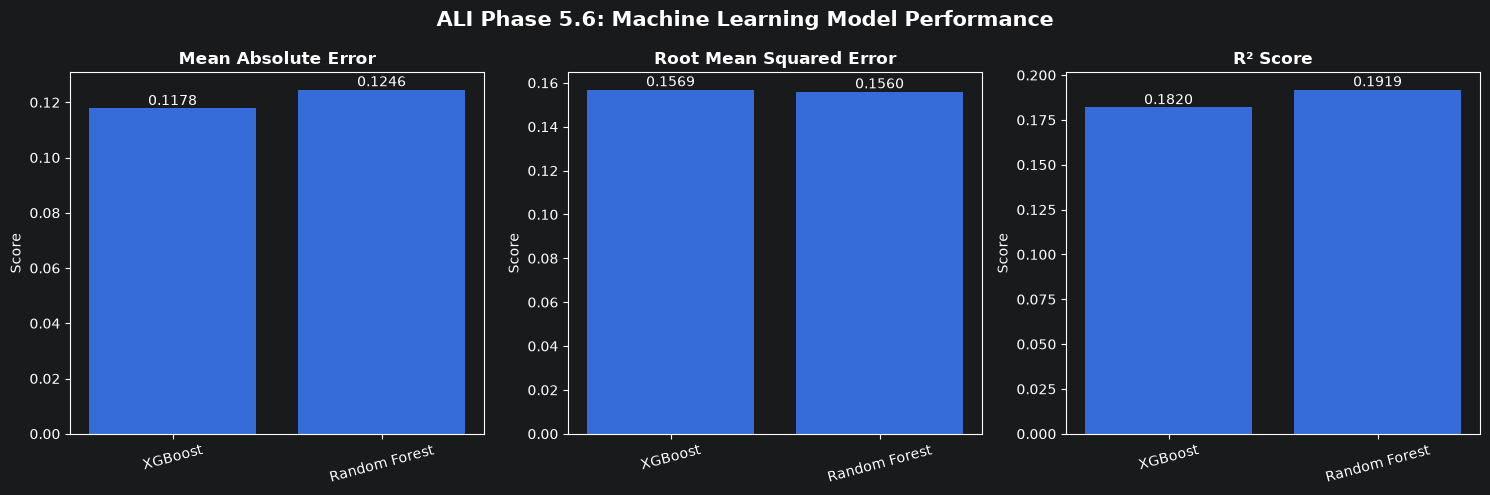

In [50]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["MAE", "RMSE", "R2"]
titles = ["Mean Absolute Error", "Root Mean Squared Error", "R² Score"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metric, title in zip(axes, metrics, titles):
    bars = ax.bar(
        results_df["Model"],
        results_df[metric]
    )

    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=15)

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.4f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

fig.suptitle(
    "ALI Phase 5.6: Machine Learning Model Performance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    "phase5_6_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [51]:
# Check whether the two road-class encodings are identical

highway_cols = [
    col for col in X.columns
    if col.startswith("highway_value_")
]

road_class_cols = [
    col for col in X.columns
    if col.startswith("road_class_")
]

print("HIGHWAY ENCODING:")
print(highway_cols)

print("\nROAD CLASS ENCODING:")
print(road_class_cols)

print("\nCOMPARISON:")

for h_col in highway_cols:
    category = h_col.replace("highway_value_", "")
    r_col = f"road_class_{category}"

    if r_col in X.columns:
        print(
            f"{category}:",
            X[h_col].equals(X[r_col])
        )

HIGHWAY ENCODING:
['highway_value_motorway', 'highway_value_primary', 'highway_value_residential', 'highway_value_secondary', 'highway_value_tertiary', 'highway_value_trunk']

ROAD CLASS ENCODING:
['road_class_motorway', 'road_class_primary', 'road_class_residential', 'road_class_secondary', 'road_class_tertiary', 'road_class_trunk']

COMPARISON:
motorway: True
primary: True
residential: True
secondary: True
tertiary: True
trunk: True


In [52]:
print("FULL X SHAPE:", X.shape)
print("TRAIN X SHAPE:", X_train.shape)
print("TEST X SHAPE:", X_test.shape)

print("\nDUPLICATE FULL X ROWS:", X.duplicated().sum())

print("\nDUPLICATE TRAIN ROWS:", X_train.duplicated().sum())

print("\nUNIQUE ROADS:", ml_data["road_segment_id"].nunique())

print("UNIQUE TIMESTAMPS:", ml_data["time"].nunique())

FULL X SHAPE: (21600, 39)
TRAIN X SHAPE: (17280, 39)
TEST X SHAPE: (4320, 39)

DUPLICATE FULL X ROWS: 0

DUPLICATE TRAIN ROWS: 0

UNIQUE ROADS: 30
UNIQUE TIMESTAMPS: 720


## PHASE 5.6.2: AUDIT FULL OSM ROAD NETWORK


In [64]:
# PHASE 5.6.2: AUDIT FULL OSM ROAD NETWORK

osm_edges_path = PROJECT_ROOT / "data" / "processed" / "phase5_network" / "osm_edges.csv"

osm_edges_full = pd.read_csv(osm_edges_path)

print("TOTAL ROAD EDGES:", len(osm_edges_full))

print("\nROAD CLASS DISTRIBUTION:")
print(osm_edges_full["highway_value"].value_counts(dropna=False))

print("\nONE-WAY VALUES:")
print(osm_edges_full["oneway_value"].value_counts(dropna=False))

print("\nMISSING VALUES:")
print(
    osm_edges_full[
        ["highway_value", "oneway_value", "maxspeed", "lanes"]
    ].isna().sum()
)

C:\Users\ginik\AppData\Local\Temp\ipykernel_5264\361488838.py:5: DtypeWarning: Columns (11: lanes, 13: maxspeed, 15: access, 16: tunnel, 20: maxspeed_value, 24: tunnel_value, 25: access_value) have mixed types. Specify dtype option on import or set low_memory=False.
  osm_edges_full = pd.read_csv(osm_edges_path)


TOTAL ROAD EDGES: 241018

ROAD CLASS DISTRIBUTION:
highway_value
residential       206498
tertiary           11602
unclassified       10311
secondary           5400
primary             3721
trunk               1798
motorway_link        329
trunk_link           310
motorway             275
primary_link         270
secondary_link       215
tertiary_link        171
living_street         56
busway                56
undefined              6
Name: count, dtype: int64

ONE-WAY VALUES:
oneway_value
False    228570
True      12448
Name: count, dtype: int64

MISSING VALUES:
highway_value         0
oneway_value          0
maxspeed         239564
lanes            236070
dtype: int64


In [65]:
from pathlib import Path
import ast
import json
import math
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import networkx as nx

warnings.filterwarnings("ignore", category=FutureWarning)

# Detect project root if it is not already defined
if "PROJECT_ROOT" not in globals():
    PROJECT_ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "data" / "raw" / "scenario.csv").exists()
    )

NETWORK_DIR = PROJECT_ROOT / "data" / "processed" / "phase5_network"
FEATURE_DIR = PROJECT_ROOT / "data" / "processed" / "phase5_features"
DATASET_DIR = PROJECT_ROOT / "data" / "processed" / "phase5_dataset"

DATASET_DIR.mkdir(parents=True, exist_ok=True)

EDGES_GEOJSON = NETWORK_DIR / "osm_edges.geojson"
GRAPHML_PATH = NETWORK_DIR / "osm_road_network.graphml"

print("Project root:", PROJECT_ROOT)
print("Edges file exists:", EDGES_GEOJSON.exists())
print("GraphML file exists:", GRAPHML_PATH.exists())
print("Dataset output:", DATASET_DIR)


Project root: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start
Edges file exists: True
GraphML file exists: True
Dataset output: C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\data\processed\phase5_dataset


In [66]:

if not EDGES_GEOJSON.exists():
    raise FileNotFoundError(f"Missing road edges file: {EDGES_GEOJSON}")

if not GRAPHML_PATH.exists():
    raise FileNotFoundError(f"Missing road network graph: {GRAPHML_PATH}")

edges_gdf = gpd.read_file(EDGES_GEOJSON)
G = ox.load_graphml(GRAPHML_PATH)

print("ROAD NETWORK AUDIT")
print("=" * 50)
print("Graph nodes:", len(G.nodes))
print("Graph edges:", len(G.edges))
print("GeoJSON edge records:", len(edges_gdf))
print("CRS:", edges_gdf.crs)

print("\nAvailable edge columns:")
print(edges_gdf.columns.tolist())

print("\nRoad classification counts:")
highway_column = (
    "highway_value" if "highway_value" in edges_gdf.columns
    else "highway" if "highway" in edges_gdf.columns
    else None
)

if highway_column is None:
    raise KeyError("No highway or highway_value column found.")

print(edges_gdf[highway_column].value_counts(dropna=False).head(30))

print("\nOne-way values:")
if "oneway" in edges_gdf.columns:
    print(edges_gdf["oneway"].value_counts(dropna=False))
elif "oneway_value" in edges_gdf.columns:
    print(edges_gdf["oneway_value"].value_counts(dropna=False))
else:
    print("No one-way field found.")


C:\Users\ginik\Documents\CODING\Portfolio-projects\Project-2-African-Logistics-Intelligence\african-logistics-intelligence-start\.venv\Lib\site-packages\geopandas\io\file.py:582: UserWarning: Could not parse column 'reversed' as JSON; leaving as string
  return pyogrio.read_dataframe(path_or_bytes, bbox=bbox, **kwargs)


ROAD NETWORK AUDIT
Graph nodes: 98859
Graph edges: 241018
GeoJSON edge records: 241018
CRS: EPSG:4326

Available edge columns:
['u', 'v', 'key', 'osmid', 'highway', 'oneway', 'reversed', 'length', 'bridge', 'name', 'lanes', 'ref', 'maxspeed', 'junction', 'access', 'tunnel', 'width', 'highway_value', 'name_value', 'maxspeed_value', 'lanes_value', 'oneway_value', 'bridge_value', 'tunnel_value', 'access_value', 'length_km', 'geometry']

Road classification counts:
highway_value
residential       206498
tertiary           11602
unclassified       10311
secondary           5400
primary             3721
trunk               1798
motorway_link        329
trunk_link           310
motorway             275
primary_link         270
secondary_link       215
tertiary_link        171
living_street         56
busway                56
undefined              6
Name: count, dtype: int64

One-way values:
oneway
False    228570
True      12448
Name: count, dtype: int64


In [67]:

def parse_osm_list(value):
    """Convert OSM list-like values into a Python list."""
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    value = str(value).strip()

    if not value:
        return []

    try:
        parsed = ast.literal_eval(value)
        if isinstance(parsed, list):
            return parsed
    except (ValueError, SyntaxError):
        pass

    return [value]


def first_osm_value(value):
    values = parse_osm_list(value)
    return str(values[0]).lower().strip() if values else None


def affirmative_osm_tag(value):
    """Return 1 only for affirmative OSM tag values."""
    values = parse_osm_list(value)

    affirmative = {"yes", "true", "1"}

    return int(any(str(v).lower().strip() in affirmative for v in values))


def tag_exists(value):
    """Return 1 when an OSM tag is present, not necessarily affirmative."""
    return int(bool(parse_osm_list(value)))


def parse_oneway(value):
    """
    Interpret OSM one-way values.
    -1 means one-way in the reverse direction, so it is still one-way.
    Missing values remain missing.
    """
    if pd.isna(value):
        return np.nan

    value = str(value).lower().strip()

    if value in {"yes", "true", "1", "-1"}:
        return 1

    if value in {"no", "false", "0"}:
        return 0

    return np.nan


# Standardize road classification
edges_gdf["road_class"] = edges_gdf[highway_column].apply(first_osm_value)

SUPPORTED_CLASSES = {
    "motorway",
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "residential"
}

edges_gdf = edges_gdf[
    edges_gdf["road_class"].isin(SUPPORTED_CLASSES)
].copy()

print("Edges in supported road classes:", len(edges_gdf))
print("\nSupported class distribution:")
print(edges_gdf["road_class"].value_counts())


Edges in supported road classes: 229294

Supported class distribution:
road_class
residential    206498
tertiary        11602
secondary        5400
primary          3721
trunk            1798
motorway          275
Name: count, dtype: int64


In [70]:
# Generate road midpoints using projected geometry

edges_projected = edges_gdf.to_crs(epsg=32631)

midpoints_projected = edges_projected.geometry.interpolate(
    0.5,
    normalized=True
)

midpoints_gdf = gpd.GeoDataFrame(
    geometry=midpoints_projected,
    crs=edges_projected.crs
).to_crs(epsg=4326)

edges_gdf["longitude"] = midpoints_gdf.geometry.x.values
edges_gdf["latitude"] = midpoints_gdf.geometry.y.values

print(
    edges_gdf[
        ["latitude", "longitude"]
    ].head()
)

print("Coordinates created successfully.")

   latitude  longitude
0  6.399850   4.266696
3  6.399009   4.269427
7  6.415196   4.095017
8  6.414389   4.094181
9  6.415599   4.094088
Coordinates created successfully.


In [73]:

# PHASE 5.6.2: BUILD THE FINAL ROAD FEATURES TABLE

# 1. Confirm that coordinates have been generated
required_coordinate_columns = ["latitude", "longitude"]

missing_coordinates = [
    col for col in required_coordinate_columns
    if col not in edges_gdf.columns
]

if missing_coordinates:
    raise ValueError(
        f"Missing coordinate columns: {missing_coordinates}. "
        "Run the road midpoint coordinate-generation cell first."
    )

# 2. Generate road segment identifiers
edges_gdf["road_segment_id"] = (
    edges_gdf["u"].astype(str) + "_" +
    edges_gdf["v"].astype(str) + "_" +
    edges_gdf["key"].astype(str)
)

# 3. Convert OSM attributes into model-friendly features
edges_gdf["is_oneway"] = (
    edges_gdf["oneway_value"].apply(parse_oneway)
)

edges_gdf["has_bridge"] = (
    edges_gdf["bridge_value"].apply(affirmative_osm_tag)
)

edges_gdf["has_tunnel"] = (
    edges_gdf["tunnel_value"].apply(affirmative_osm_tag)
)

edges_gdf["has_maxspeed"] = (
    edges_gdf["maxspeed_value"].apply(tag_exists)
)

edges_gdf["has_lanes"] = (
    edges_gdf["lanes_value"].apply(tag_exists)
)

edges_gdf["has_name"] = (
    edges_gdf["name_value"].apply(tag_exists)
)

edges_gdf["has_access"] = (
    edges_gdf["access_value"].apply(tag_exists)
)

# 4. Ensure length is numeric
edges_gdf["length_km"] = pd.to_numeric(
    edges_gdf["length_km"],
    errors="coerce"
)

# 5. Define the final feature columns
road_feature_columns = [
    "road_segment_id",
    "u",
    "v",
    "key",
    "road_class",
    "length_km",
    "latitude",
    "longitude",
    "is_oneway",
    "has_bridge",
    "has_tunnel",
    "has_maxspeed",
    "has_lanes",
    "has_name",
    "has_access",
    "u_degree",
    "v_degree",
    "u_is_junction",
    "v_is_junction",
    "endpoint_junction_count",
    "mean_endpoint_degree",
    "max_endpoint_degree",
    "min_endpoint_degree"
]

# 6. Check that all required features exist
missing_features = [
    col for col in road_feature_columns
    if col not in edges_gdf.columns
]

if missing_features:
    raise ValueError(
        f"Missing road feature columns: {missing_features}"
    )

# 7. Build a fresh DataFrame
road_features = edges_gdf[
    road_feature_columns
].copy()

# 8. Remove records with invalid geometry-derived values
road_features = road_features.dropna(
    subset=["latitude", "longitude", "length_km"]
)

road_features = road_features[
    (road_features["length_km"] > 0) &
    road_features["latitude"].between(-90, 90) &
    road_features["longitude"].between(-180, 180)
].copy()

# 9. Verify the result
print("ROAD FEATURES CREATED")
print("=" * 45)

print("Total road features:", len(road_features))
print("Unique road segments:",
      road_features["road_segment_id"].nunique())

print("\nCoordinate sample:")
print(
    road_features[
        ["road_segment_id", "latitude", "longitude"]
    ].head()
)

print("\nMissing values:")
print(
    road_features[
        ["latitude", "longitude", "length_km"]
    ].isna().sum()
)

print("\nFinal feature columns:")
print(road_features.columns.tolist())


ROAD FEATURES CREATED
Total road features: 229294
Unique road segments: 229294

Coordinate sample:
            road_segment_id  latitude  longitude
0  3202618256_10175580642_0  6.399850   4.266696
3  3202618257_10175580617_0  6.399009   4.269427
7   3202622663_6622846681_0  6.415196   4.095017
8  3202622663_12114539856_0  6.414389   4.094181
9   3202622663_3202622665_0  6.415599   4.094088

Missing values:
latitude     0
longitude    0
length_km    0
dtype: int64

Final feature columns:
['road_segment_id', 'u', 'v', 'key', 'road_class', 'length_km', 'latitude', 'longitude', 'is_oneway', 'has_bridge', 'has_tunnel', 'has_maxspeed', 'has_lanes', 'has_name', 'has_access', 'u_degree', 'v_degree', 'u_is_junction', 'v_is_junction', 'endpoint_junction_count', 'mean_endpoint_degree', 'max_endpoint_degree', 'min_endpoint_degree']


In [74]:

SAMPLE_SIZE = 5000
GRID_SIZE_DEGREES = 0.05
RANDOM_STATE = 42

if len(road_features) < SAMPLE_SIZE:
    raise ValueError(
        f"Only {len(road_features)} eligible edges are available; "
        f"cannot sample {SAMPLE_SIZE}."
    )

sampling_frame = road_features.copy()

sampling_frame["grid_lat"] = (
    np.floor(sampling_frame["latitude"] / GRID_SIZE_DEGREES)
    * GRID_SIZE_DEGREES
)

sampling_frame["grid_lon"] = (
    np.floor(sampling_frame["longitude"] / GRID_SIZE_DEGREES)
    * GRID_SIZE_DEGREES
)

strata_columns = ["road_class", "grid_lat", "grid_lon"]

strata_sizes = (
    sampling_frame.groupby(strata_columns, observed=True)
    .size()
    .rename("population")
    .reset_index()
)

# Proportional allocation using the largest-remainder method
strata_sizes["exact_quota"] = (
    strata_sizes["population"] / len(sampling_frame) * SAMPLE_SIZE
)

strata_sizes["quota"] = np.floor(
    strata_sizes["exact_quota"]
).astype(int)

remaining = SAMPLE_SIZE - strata_sizes["quota"].sum()

strata_sizes["remainder"] = (
    strata_sizes["exact_quota"] - strata_sizes["quota"]
)

strata_sizes = strata_sizes.sort_values(
    "remainder", ascending=False
).reset_index(drop=True)

strata_sizes.loc[:remaining - 1, "quota"] += 1

quota_lookup = {
    (row.road_class, row.grid_lat, row.grid_lon): int(row.quota)
    for row in strata_sizes.itertuples()
}

sample_parts = []

for stratum, group in sampling_frame.groupby(
    strata_columns, observed=True, sort=False
):
    quota = quota_lookup[stratum]

    if quota > 0:
        sample_parts.append(
            group.sample(
                n=quota,
                replace=False,
                random_state=RANDOM_STATE
            )
        )

road_sample_5000 = pd.concat(
    sample_parts,
    ignore_index=True
)

road_sample_5000 = road_sample_5000.drop(
    columns=["grid_lat", "grid_lon"]
)

if len(road_sample_5000) != SAMPLE_SIZE:
    raise ValueError(
        f"Expected {SAMPLE_SIZE} roads, got {len(road_sample_5000)}."
    )

if road_sample_5000["road_segment_id"].nunique() != SAMPLE_SIZE:
    raise ValueError("Duplicate road segment IDs found in sample.")

print("SAMPLE SIZE:", len(road_sample_5000))
print("UNIQUE ROAD SEGMENTS:", road_sample_5000["road_segment_id"].nunique())

print("\nSAMPLED ROAD CLASS DISTRIBUTION:")
print(road_sample_5000["road_class"].value_counts())

print("\nSAMPLED GEOGRAPHIC COVERAGE:")
print("Latitude range:",
      road_sample_5000["latitude"].min(),
      "to",
      road_sample_5000["latitude"].max())

print("Longitude range:",
      road_sample_5000["longitude"].min(),
      "to",
      road_sample_5000["longitude"].max())

road_sample_5000.to_parquet(
    DATASET_DIR / "road_sample_5000.parquet",
    index=False
)


SAMPLE SIZE: 5000
UNIQUE ROAD SEGMENTS: 5000

SAMPLED ROAD CLASS DISTRIBUTION:
road_class
residential    4503
tertiary        256
secondary       117
primary          80
trunk            39
motorway          5
Name: count, dtype: int64

SAMPLED GEOGRAPHIC COVERAGE:
Latitude range: 6.376963147673434 to 6.691971939961591
Longitude range: 2.7065688141973907 to 4.333034149999115


ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

In [ ]:

WEATHER_COLUMNS = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "rain",
    "wind_speed_10m",
    "weather_code"
]

required_weather_columns = ["time"] + WEATHER_COLUMNS

missing_weather_columns = [
    col for col in required_weather_columns
    if col not in ml_data.columns
]

if missing_weather_columns:
    raise KeyError(
        f"Missing weather columns in ml_data: {missing_weather_columns}"
    )

weather_hourly = (
    ml_data[required_weather_columns]
    .drop_duplicates(subset=["time"])
    .copy()
)

weather_hourly["time"] = pd.to_datetime(
    weather_hourly["time"],
    errors="coerce"
)

weather_hourly = weather_hourly.dropna(
    subset=["time"]
).sort_values("time").reset_index(drop=True)

if weather_hourly["time"].duplicated().any():
    raise ValueError("Duplicate timestamps found in weather data.")

if len(weather_hourly) != 720:
    raise ValueError(
        f"Expected 720 hourly weather records, found {len(weather_hourly)}. "
        "Inspect the original weather dataset before continuing."
    )

print("WEATHER RECORDS:", len(weather_hourly))
print("FIRST TIMESTAMP:", weather_hourly["time"].min())
print("LAST TIMESTAMP:", weather_hourly["time"].max())
print("\nWEATHER MISSING VALUES:")
print(weather_hourly.isna().sum())


In [ ]:

BASE_SPEEDS = {
    "motorway": 70,
    "trunk": 60,
    "primary": 45,
    "secondary": 35,
    "tertiary": 30,
    "residential": 20
}

def calculate_time_multiplier(hour):
    if 7 <= hour <= 9:
        return 0.65
    elif 16 <= hour <= 19:
        return 0.60
    elif 10 <= hour <= 15:
        return 0.85
    elif 20 <= hour <= 22:
        return 0.90
    return 1.0


def calculate_weather_multiplier(precipitation):
    if precipitation >= 5:
        return 0.75
    elif precipitation >= 2:
        return 0.85
    elif precipitation > 0:
        return 0.95
    return 1.0


# Confirm every sampled road class has an assigned base speed
unsupported_classes = (
    set(road_sample_5000["road_class"].unique())
    - set(BASE_SPEEDS.keys())
)

if unsupported_classes:
    raise ValueError(
        f"No base speed assumption defined for: {unsupported_classes}"
    )

weather_hourly["hour"] = weather_hourly["time"].dt.hour
weather_hourly["day_of_week"] = weather_hourly["time"].dt.dayofweek
weather_hourly["is_weekend"] = (
    weather_hourly["day_of_week"] >= 5
).astype("int8")

weather_hourly["time_multiplier"] = (
    weather_hourly["hour"].apply(calculate_time_multiplier)
)

weather_hourly["weather_multiplier"] = (
    weather_hourly["precipitation"]
    .fillna(0)
    .apply(calculate_weather_multiplier)
)

print(weather_hourly.head())
